In [3]:
dataset = "Placement_Data_Full_Class.csv"
df = pd.read_csv(dataset)


In [4]:
print(df.head())

   sl_no gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p  \
0      1      M  67.00   Others  91.00   Others  Commerce     58.00   
1      2      M  79.33  Central  78.33   Others   Science     77.48   
2      3      M  65.00  Central  68.00  Central      Arts     64.00   
3      4      M  56.00  Central  52.00  Central   Science     52.00   
4      5      M  85.80  Central  73.60  Central  Commerce     73.30   

    degree_t workex  etest_p specialisation  mba_p      status    salary  
0   Sci&Tech     No     55.0         Mkt&HR  58.80      Placed  270000.0  
1   Sci&Tech    Yes     86.5        Mkt&Fin  66.28      Placed  200000.0  
2  Comm&Mgmt     No     75.0        Mkt&Fin  57.80      Placed  250000.0  
3   Sci&Tech     No     66.0         Mkt&HR  59.43  Not Placed       NaN  
4  Comm&Mgmt     No     96.8        Mkt&Fin  55.50      Placed  425000.0  


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB
None


In [6]:
print(df.isnull().sum())

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df = df.drop(columns=['sl_no', 'salary'], errors='ignore')

kategorik_sutunlar = df.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in kategorik_sutunlar:
    df[col] = le.fit_transform(df[col])

X = df.drop('status', axis=1)
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("\n>>> BAŞARILI: Kaggle veri seti çekildi, ön işleme yapıldı ve bölündü!")
print(f"Toplam Veri Sayısı  : {len(df)}")
print(f"Eğitim Seti (%70)   : {len(X_train)}")
print(f"Test Seti (%30)     : {len(X_test)}")
print(f"\nModelde Kullanılacak Özellikler ({X.shape[1]} adet):")
print(list(X.columns))


>>> BAŞARILI: Kaggle veri seti çekildi, ön işleme yapıldı ve bölündü!
Toplam Veri Sayısı  : 215
Eğitim Seti (%70)   : 150
Test Seti (%30)     : 65

Modelde Kullanılacak Özellikler (12 adet):
['gender', 'ssc_p', 'ssc_b', 'hsc_p', 'hsc_b', 'hsc_s', 'degree_p', 'degree_t', 'workex', 'etest_p', 'specialisation', 'mba_p']



MODEL: Lojistik Regresyon
Doğruluk Skoru (Accuracy) : 0.8154 (%81.54)

Karmaşıklık Matrisi (Confusion Matrix):
[[11  9]
 [ 3 42]]

Sınıflandırma Raporu (Classification Report):
                precision    recall  f1-score   support

Not Placed (0)       0.79      0.55      0.65        20
    Placed (1)       0.82      0.93      0.88        45

      accuracy                           0.82        65
     macro avg       0.80      0.74      0.76        65
  weighted avg       0.81      0.82      0.80        65


MODEL: Karar Ağacı (Decision Tree)
Doğruluk Skoru (Accuracy) : 0.7385 (%73.85)

Karmaşıklık Matrisi (Confusion Matrix):
[[ 9 11]
 [ 6 39]]

Sınıflandırma Raporu (Classification Report):
                precision    recall  f1-score   support

Not Placed (0)       0.60      0.45      0.51        20
    Placed (1)       0.78      0.87      0.82        45

      accuracy                           0.74        65
     macro avg       0.69      0.66      0.67        65
  weighted avg

,Lojistik Regresyon,Karar Ağacı (Decision Tree),KNN (K-Nearest Neighbors),SVM (Support Vector Machine)
Accuracy,0.8154,0.7385,0.7692,0.7538
Precision (Prec),0.8235,0.7800,0.7885,0.7959
Recall (Rec),0.9333,0.8667,0.9111,0.8667
F1-Score (F-Score),0.8750,0.8211,0.8454,0.8298


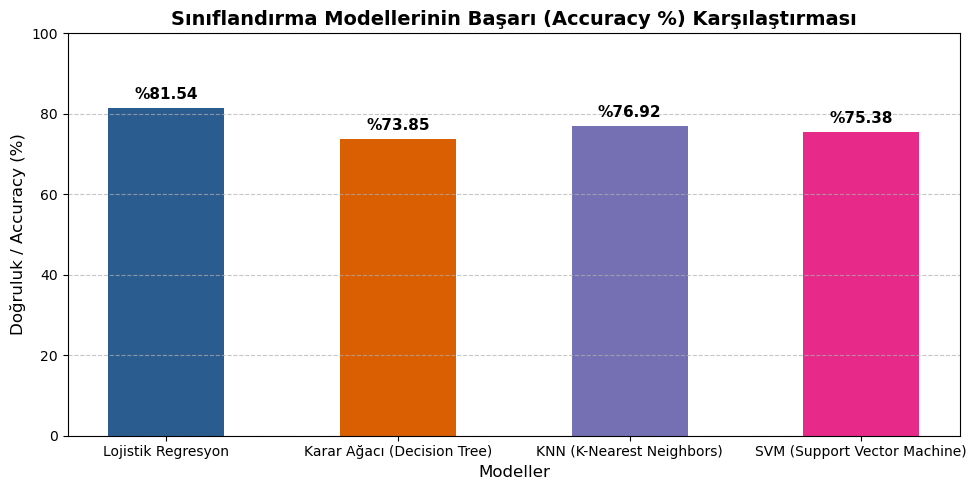

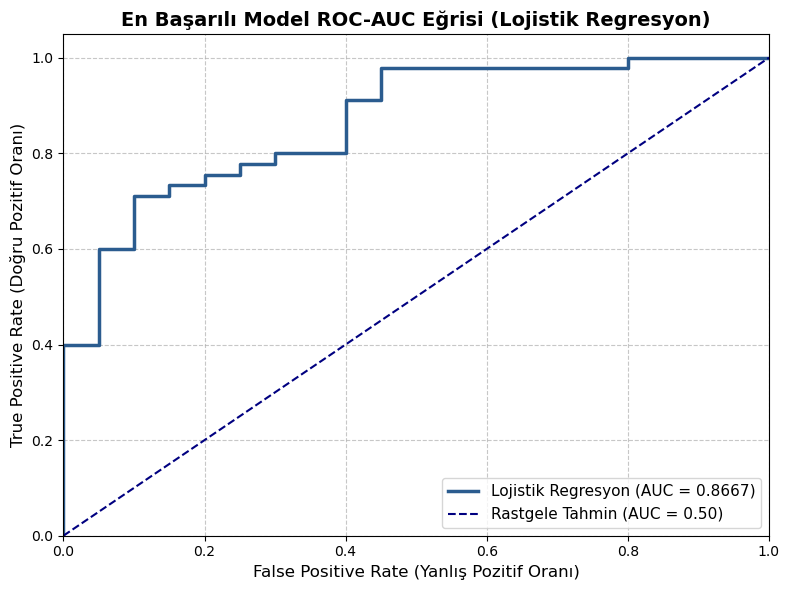

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score
)

# Modeller (SVM için ROC-AUC olasılık hesabı adına probability=True eklendi)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# 2. ÖZEL ÖLÇEKLENDİRME (SCALING)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. MODELLERİN EĞİTİLMESİ VE DEĞERLENDİRİLMESİ
modeller = {
    "Lojistik Regresyon": LogisticRegression(max_iter=1000, random_state=42),
    "Karar Ağacı (Decision Tree)": DecisionTreeClassifier(random_state=42),
    "KNN (K-Nearest Neighbors)": KNeighborsClassifier(n_neighbors=5),
    "SVM (Support Vector Machine)": SVC(kernel='rbf', probability=True, random_state=42)
}

dogruluk_skorlari = {}
metrikler_dict = {}
tahmin_olasiliklari = {}

for model_adi, model in modeller.items():
    print(f"\n{'='*60}\nMODEL: {model_adi}\n{'='*60}")
    
    if model_adi in ["Lojistik Regresyon", "KNN (K-Nearest Neighbors)", "SVM (Support Vector Machine)"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]
        
    # Başarı metriklerinin hesaplanması
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    
    dogruluk_skorlari[model_adi] = acc
    tahmin_olasiliklari[model_adi] = y_proba
    
    metrikler_dict[model_adi] = {
        "Accuracy": round(acc, 4),
        "Precision (Prec)": round(prec, 4),
        "Recall (Rec)": round(rec, 4),
        "F1-Score (F-Score)": round(f1, 4)
    }
    
    cm = confusion_matrix(y_test, y_pred)
    cr = classification_report(y_test, y_pred, target_names=['Not Placed (0)', 'Placed (1)'])
    
    print(f"Doğruluk Skoru (Accuracy) : {acc:.4f} (%{acc*100:.2f})")
    print("\nKarmaşıklık Matrisi (Confusion Matrix):")
    print(cm)
    print("\nSınıflandırma Raporu (Classification Report):")
    print(cr)

# ==========================================
# 4. MODEL PERFORMANS KARŞILAŞTIRMA TABLOSU
# ==========================================
df_metrikler = pd.DataFrame(metrikler_dict)

print("\n" + "="*60)
print("MODEL PERFORMANS KARŞILAŞTIRMA TABLOSU")
print("="*60)
display(df_metrikler)  # Jupyter Notebook üzerinde şık tablo görünümü için

# ==========================================
# 5. BAŞARI SKORLARININ GRAFİK İLE KARŞILAŞTIRILMASI
# ==========================================
plt.figure(figsize=(10, 5))
modeller_listesi = list(dogruluk_skorlari.keys())
skorlar_listesi = [val * 100 for val in dogruluk_skorlari.values()]

renkler = ['#2b5c8f', '#d95f02', '#7570b3', '#e7298a']
bars = plt.bar(modeller_listesi, skorlar_listesi, color=renkler, width=0.5)

plt.title('Sınıflandırma Modellerinin Başarı (Accuracy %) Karşılaştırması', fontsize=14, fontweight='bold')
plt.xlabel('Modeller', fontsize=12)
plt.ylabel('Doğruluk / Accuracy (%)', fontsize=12)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yukseklik = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., yukseklik + 1.5,
             f'%{yukseklik:.2f}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==========================================
# 6. EN BAŞARILI MODEL İÇİN ROC-AUC EĞRİSİ
# ==========================================
en_iyi_model_adi = max(dogruluk_skorlari, key=dogruluk_skorlari.get)
en_iyi_y_proba = tahmin_olasiliklari[en_iyi_model_adi]

fpr, tpr, _ = roc_curve(y_test, en_iyi_y_proba)
auc_skoru = roc_auc_score(y_test, en_iyi_y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'{en_iyi_model_adi} (AUC = {auc_skoru:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Rastgele Tahmin (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Yanlış Pozitif Oranı)', fontsize=12)
plt.ylabel('True Positive Rate (Doğru Pozitif Oranı)', fontsize=12)
plt.title(f'En Başarılı Model ROC-AUC Eğrisi ({en_iyi_model_adi})', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()